In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

# Load the Iris dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

# Display the dataset
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:

# Check dataset information
print("Dataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [ ]:

# Check missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [ ]:

# Count the number of flowers in each species
print("Species Distribution:")
print(df["species"].value_counts())


Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [ ]:

# Display statistical summary of numerical columns
print("Statistical Summary:")
display(df.describe())


Statistical Summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


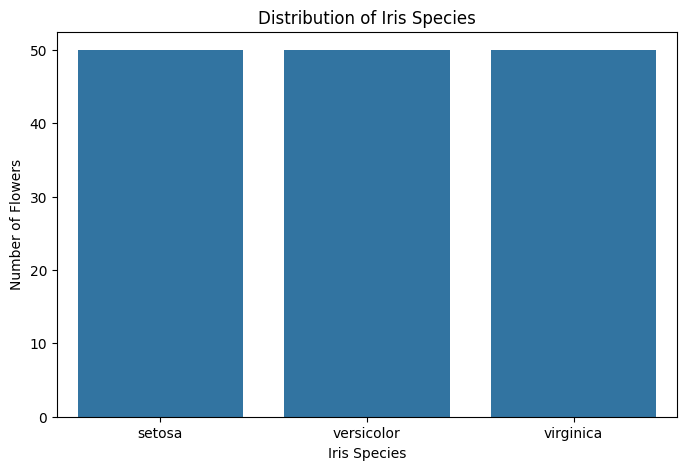

In [ ]:

# Count the flowers in each species
species_counts = df["species"].value_counts()

# Create the bar chart
plt.figure(figsize=(8, 5))
sns.barplot(
    x=species_counts.index,
    y=species_counts.values
)

plt.title("Distribution of Iris Species")
plt.xlabel("Iris Species")
plt.ylabel("Number of Flowers")
plt.show()


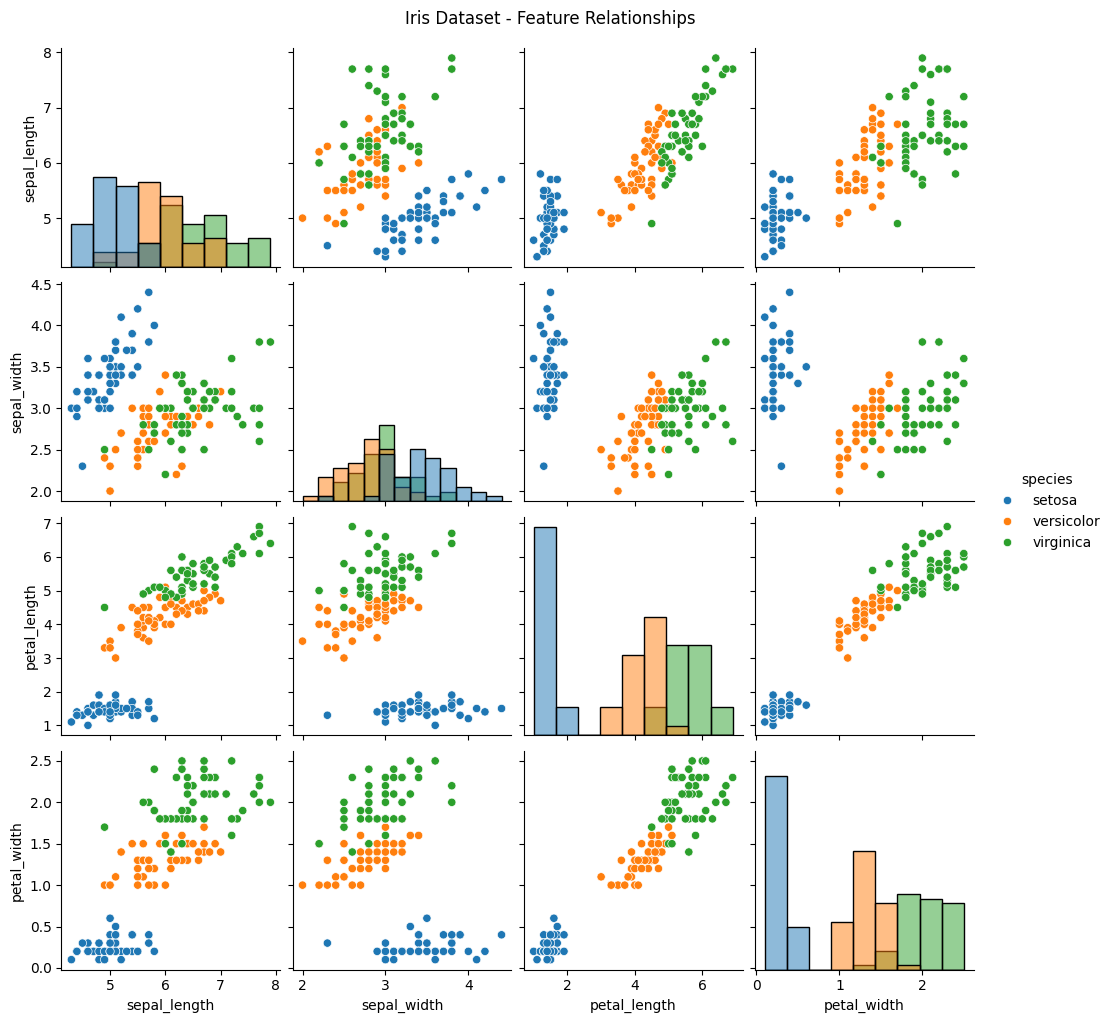

In [ ]:

# Create a pairplot to compare Iris features
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle(
    "Iris Dataset - Feature Relationships",
    y=1.02
)

plt.show()


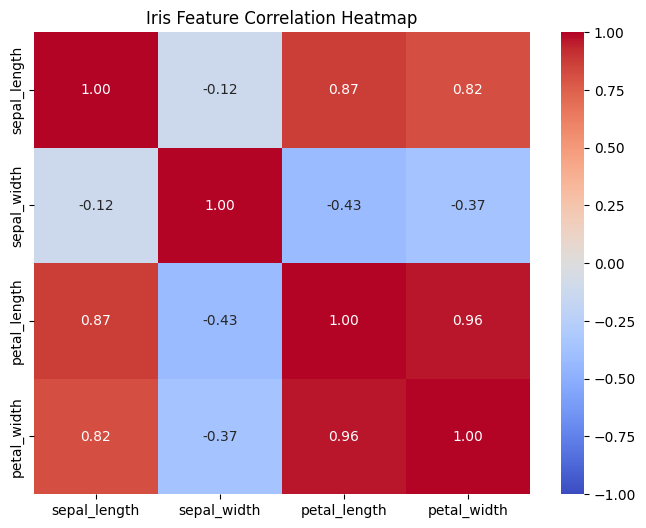

In [ ]:

# Select only numerical features
features = df[
    ["sepal_length", "sepal_width",
     "petal_length", "petal_width"]
]

# Calculate correlation
correlation_matrix = features.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Iris Feature Correlation Heatmap")
plt.show()


In [ ]:

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Total samples:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Total samples: 150
Training samples: 120
Testing samples: 30


In [ ]:

# Create the feature scaler
scaler = StandardScaler()

# Learn scaling values from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to test data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)


Feature scaling completed successfully!
Scaled training data shape: (120, 4)
Scaled testing data shape: (30, 4)


In [ ]:

# Create the Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000)

# Train using the scaled training data
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [ ]:

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

# Train using the training data
tree_model.fit(X_train_scaled, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [ ]:
print("Models ready for evaluation:")
print("1. Logistic Regression")
print("2. Decision Tree")

Models ready for evaluation:
1. Logistic Regression
2. Decision Tree


In [ ]:

# Make predictions on the test dataset
y_pred_logistic = logistic_model.predict(X_test_scaled)
y_pred_tree = tree_model.predict(X_test_scaled)

# Calculate evaluation metrics
results = []

for name, predictions in [
    ("Logistic Regression", y_pred_logistic),
    ("Decision Tree", y_pred_tree)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro"
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro"
        ),
        "F1-Score": f1_score(
            y_test, predictions, average="macro"
        )
    })

# Display the comparison table
results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(results_df.round(3))


Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933,0.933,0.933,0.933
1,Decision Tree,0.933,0.933,0.933,0.933


In [ ]:

print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, y_pred_logistic))

print("\nDECISION TREE REPORT")
print(classification_report(y_test, y_pred_tree))


LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


DECISION TREE REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



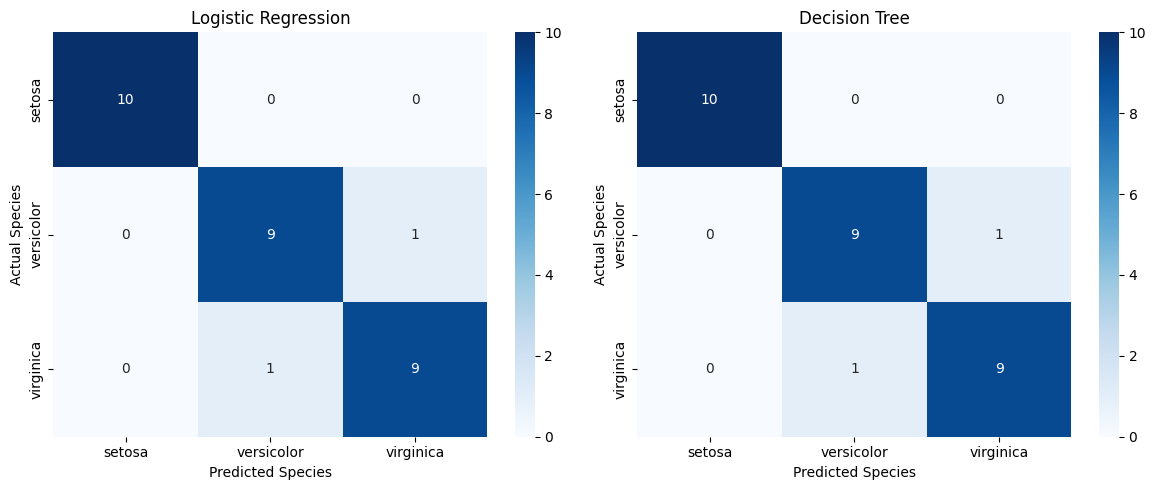

In [ ]:
# Define the species order
species_order = ["setosa", "versicolor", "virginica"]
# Define numeric representations corresponding to the classes
numeric_labels = [0, 1, 2]

# Create two side-by-side heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

predictions_list = [
    ("Logistic Regression", y_pred_logistic),
    ("Decision Tree", y_pred_tree)
]

for ax, (name, predictions) in zip(axes, predictions_list):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=numeric_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=species_order,
        yticklabels=species_order,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

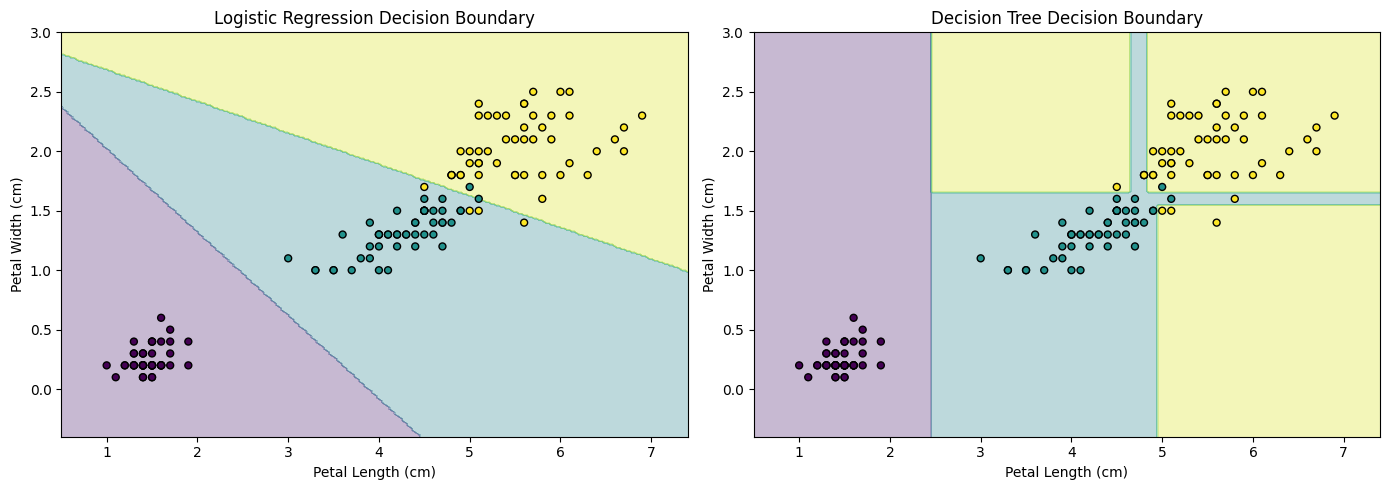

In [ ]:

# Select two features for visualization
X_2d = df[["petal_length", "petal_width"]]
y_2d = df["species"]

# Split the two-feature dataset
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.20,
    random_state=42,
    stratify=y_2d
)

# Create models for the 2D plots
models_2d = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=4
    )
}

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, classifier) in zip(axes, models_2d.items()):

    # Scale and train the model using only the two selected features
    model_2d = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])

    model_2d.fit(X_train_2d, y_train_2d)

    # Create a grid across the feature ranges
    x_min = X_2d["petal_length"].min() - 0.5
    x_max = X_2d["petal_length"].max() + 0.5
    y_min = X_2d["petal_width"].min() - 0.5
    y_max = X_2d["petal_width"].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = pd.DataFrame({
        "petal_length": xx.ravel(),
        "petal_width": yy.ravel()
    })

    # Predict the species for each grid point
    Z = model_2d.predict(grid)

    # Convert class names into numeric values for plotting
    species_map = {
        "setosa": 0,
        "versicolor": 1,
        "virginica": 2
    }

    Z = pd.Series(Z).map(species_map).to_numpy()
    Z = Z.reshape(xx.shape)

    # Draw the decision regions
    ax.contourf(
        xx, yy, Z,
        alpha=0.3,
        cmap="viridis"
    )

    # Display the flower samples
    ax.scatter(
        X_2d["petal_length"],
        X_2d["petal_width"],
        c=y_2d.map(species_map),
        cmap="viridis",
        edgecolors="black",
        s=25
    )

    ax.set_title(name + " Decision Boundary")
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")

plt.tight_layout()
plt.show()


# Conclusion

In this project, I implemented a supervised multi-class classification pipeline using the Iris dataset. I performed exploratory data analysis using statistical summaries, a species distribution chart, a pairplot, and a feature correlation heatmap.

I divided the dataset into 80% training data and 20% testing data. I applied StandardScaler and trained two machine learning models: Logistic Regression and Decision Tree.

I evaluated both models using accuracy, macro-precision, macro-recall, and macro-F1-score. I also visualized the classification results using confusion matrix heatmaps and decision-boundary plots based on petal length and petal width.

**Model comparison:**
- Logistic Regression accuracy: [enter your result]
- Decision Tree accuracy: [enter your result]

Based on the evaluation metrics, [enter the better-performing model] performed better on the test dataset. This project demonstrates the complete machine learning workflow, from data exploration and preprocessing to model training, evaluation, and visualization